In [11]:
import functions as AvT
import xarray as xr
import numpy as np
import mne
from datetime import datetime
import os
import math
import copy

Optional: load TFR

In [ ]:
directory_name = "labelled_data_200hz.nc accuracy n_trials=9390 baseline=(None, -0.15) decim=1 steps=30 2026-08-03-tfr"

tfr_events = []

for f in os.scandir(f"output/{directory_name}"):
    if f.name.startswith("event"):
        tfr_events.append(mne.time_frequency.read_tfrs(f.path))
    if f.name.startswith("total"):
        tfr = mne.time_frequency.read_tfrs(f.path)
    

Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\labelled_data_200hz.nc accuracy n_trials=9390 baseline=(None, -0.15) decim=1 steps=30 2026-08-03-tfr\event 0_tfr.hdf5 ...


KeyboardInterrupt: 

1. Collecting data

In [2]:
#parameters
ds_name = "labelled_data_200hz.nc"      #file name for the dataset
condition = "speed"                     #condition
force = "high"                          #force
info_fname = "S1_epo.fif"

#create datasets
ds = xr.open_dataset(f"data/{ds_name}")
ds = ds.where(ds["condition"] == condition, drop=True)
ds = ds.where(ds["force"] == force, drop=True)
sfreq = ds.attrs['sfreq']

#create probabilities array
probs_shape = ds.probabilities.values.shape
probs = ds.probabilities.values.reshape(-1, probs_shape[2], probs_shape[3]) 

#create eeg array
eeg_shape = ds.data.values.shape
eeg = ds.data.values.reshape(-1, eeg_shape[2], eeg_shape[3]) 
#info object
info = mne.io.read_info(f"data/{info_fname}")

old_info = info.copy()

info = mne.create_info(
    ch_names=ds.channel.values.tolist(),
    sfreq=ds.attrs["sfreq"],
    ch_types="eeg",
)
with info._unlock():
    info["lowpass"] = float(ds.attrs["lowpass"])
    info["highpass"] = float(ds.attrs["highpass"])

montage = old_info.get_montage()
if montage is not None:
    info.set_montage(montage)

#del ds delete dataset to save memory

2. Preparing epochs

In [3]:
#parameters
n_trials = 200                                  #n_trials for the TFR
batch_size = 200                                #batch size for the processing of the TFRs

#filter valid trials
valid_trials = ~np.isnan(eeg[:, :, 0]).any(axis=1)
n_valid_trials = eeg[valid_trials].shape[0]
if n_valid_trials < n_trials:
    n_trials = n_valid_trials
    print(f"There are not enough valid trials to complete your request, we changed the number of trials to {n_valid_trials}")

#prepare epochs
eeg_batches = []

for batch in range(math.ceil(n_trials/batch_size)):
    lower = batch*batch_size
    upper = batch*batch_size+min(batch_size, n_trials-batch_size*batch)
    eeg_batches.append(eeg[valid_trials][lower:upper, :, :])

del eeg #delete eeg data to save memory

probs = probs[valid_trials][:n_trials, :, :]

#create epochs
epochs_batches = []

for batch in eeg_batches:
    epochs_batches.append(mne.EpochsArray(np.nan_to_num(batch, nan=0.0), info, tmin=-0.2))

Not setting metadata
200 matching events found
No baseline correction applied
0 projection items activated


3. Generating TFR events

In [4]:
#parameters
n_jobs = 1                                                              #parallel processes
baseline = (None, -0.15)                                                #TFR baseline       
steps = 30                                                              #n_steps within the frequency interval
save = False                                                            #True if TFR are saved to .hdf5 files

low_freq = 2                                                            #lower bound frequency interval
high_freq = 40                                                          #higher bound frequency interval

low_cycle = 3                                                           #lower bound n_cycle interval
high_cycle = 8                                                          #higher bound n_cycle interval

t_left = 40                                                             #n_samples before the event onset
t_right = 40                                                            #n_samples after the event onset

log = True                                                              #will output the proces if true

freqs = list(np.logspace(np.log10(low_freq), np.log10(high_freq), steps))
n_cycles = list(np.logspace(np.log10(low_cycle), np.log10(high_cycle), steps))


In [5]:
#per epoch batch create a TFR and TFR events
for n, epochs in enumerate(epochs_batches):
    print(f"batch: {n+1}/{len(epochs_batches)}")
    if n == 0:
        #create TFR and TFR events
        tfr = AvT.get_tfr(epochs, freqs, baseline, jobs=n_jobs, cycles=n_cycles)
        tfr_events = AvT.get_tfr_events(tfr, probs, t_left, t_right, sfreq, log=log)
        tfr = tfr.average()
    else:
        temp_tfr = AvT.get_tfr(epochs, freqs, baseline, jobs=n_jobs, cycles=n_cycles)
        temp_tfr_events = AvT.get_tfr_events(temp_tfr, probs, t_left, t_right, sfreq, log=log)
        temp_tfr = temp_tfr.average()

        #add TFR and TFR events to current instances
        for n, temp_tfr_event in enumerate(temp_tfr_events):
                    tfr_events[n].__add__(temp_tfr_event)
        tfr.__add__(temp_tfr)

#divide TFR and TFR events by the amount of batches
tfr._data/(n_trials/batch_size)
for tfr_event in tfr_events:
    tfr_event._data/(n_trials/batch_size)

#save TFR
if save:
    directory_name = f"output/{ds_name} {condition} n_trials={n_trials} baseline={baseline} steps={steps} {datetime.today().strftime('%Y-%m-%d')}-tfr"
    os.mkdir(directory_name)

    tfr.save(f"{directory_name}/total_tfr.hdf5", overwrite=True)

    for n, tfr_event in enumerate(tfr_events):
        tfr_event.save(f"{directory_name}/event {n}_tfr.hdf5", overwrite=True)

batch: 1/1
Applying baseline correction (mode: logratio)


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\baseline.py:115: RuntimeWarning: divide by zero encountered in log10
  np.log10(d, out=d)


retreiving TFR events
retreived TFR events succesfully


In [ ]:
#per epoch batch create a ITC and ITC events
for n, epochs in enumerate(epochs_batches):
    print(f"batch: {n+1}/{len(epochs_batches)}")
    if n == 0:
        #create TFR and TFR events
        itc = AvT.get_itc(epochs, freqs, jobs=n_jobs, cycles=n_cycles)
        #itc_events = AvT.get_itc_events(epochs, probs, t_left, t_right, sfreq, log=log)
    else:
        temp_itc = AvT.get_itc(epochs, freqs, baseline, jobs=n_jobs, cycles=n_cycles)
        #temp_itc_events = AvT.get_itc_events(epochs, probs, t_left, t_right, sfreq, log=log)

        """
        #add TFR and TFR events to current instances
        for n, temp_itc_event in enumerate(temp_itc_events):
                    itc_events[n].__add__(temp_itc_event)
        itc.__add__(temp_itc)
        """

#divide TFR and TFR events by the amount of batches
itc._data/(n_trials/batch_size)
"""
for itc_event in itc_events:
    itc_event._data/(n_trials/batch_size)
"""

batch: 1/1


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\time_frequency\tfr.py:750: RuntimeWarning: invalid value encountered in divide
  plf += tfr / tfr_abs  # phase


'\nfor itc_event in itc_events:\n    itc_event._data/(n_trials/batch_size)\n'

In [128]:
test_epochs = copy.copy(epochs_batches[0])
print(test_epochs._data.shape)

(200, 64, 832)


Not setting metadata-
200 matching events found
No baseline correction applied
0 projection items activated


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\time_frequency\tfr.py:750: RuntimeWarning: invalid value encountered in divide
  plf += tfr / tfr_abs  # phase


No baseline correction applied


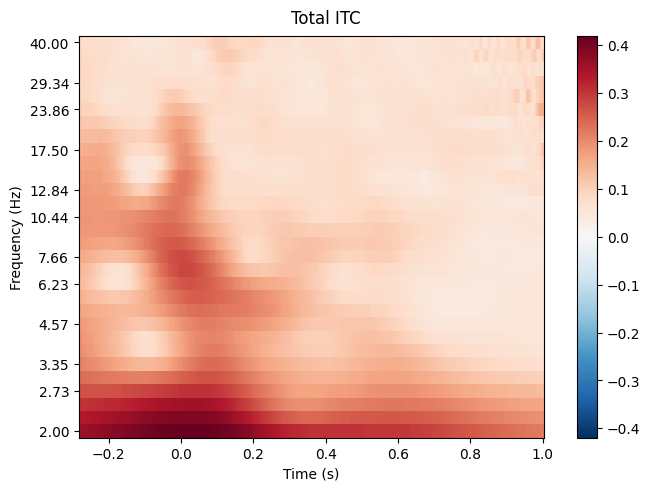

Not setting metadata-
200 matching events found
No baseline correction applied
0 projection items activated


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\time_frequency\tfr.py:750: RuntimeWarning: invalid value encountered in divide
  plf += tfr / tfr_abs  # phase


No baseline correction applied


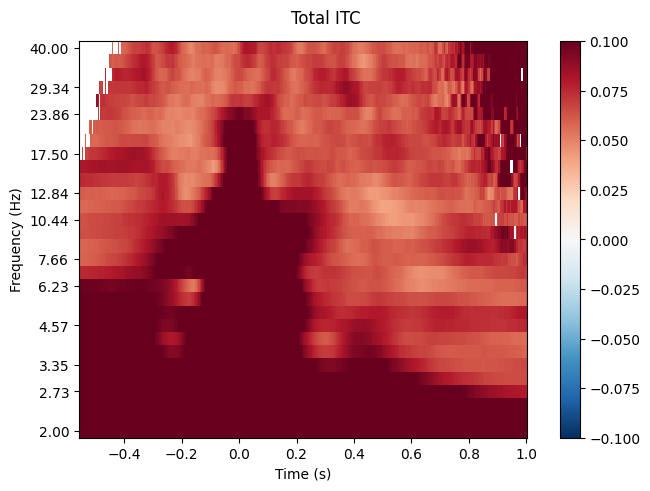

Not setting metadata-
200 matching events found
No baseline correction applied
0 projection items activated


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\time_frequency\tfr.py:750: RuntimeWarning: invalid value encountered in divide
  plf += tfr / tfr_abs  # phase


No baseline correction applied


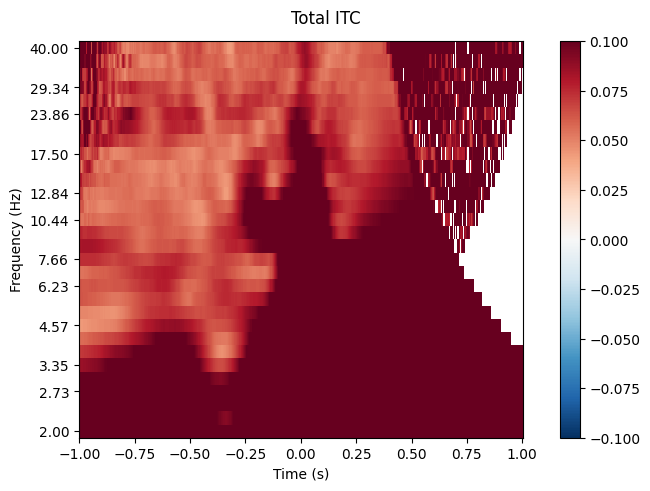

In [175]:
for event in range(probs.shape[1]):
        if log: print(f"event: {event}, trial: ----", end='\r')                                      
        itc_event = []

        #add the centred data for every trail using context
        for trial in range(test_epochs._data.shape[0]):
            if log: print(f"event: {event}, trial: {trial + 1}", end='\r', flush=True)                 
            _, center, _ = AvT.get_context(probs[trial, event, :], 20, 20)
            center = int(center) - 1
            if center > 0:
                itc_event.append((test_epochs._data[trial, :, :center], test_epochs._data[trial, :, center], test_epochs._data[trial, :, center+1:]))

        if event not in [0,3]:
            left, data = center_matrix(itc_event)
            itc = mne.EpochsArray(np.nan_to_num(data, nan=0.0), info, tmin=-(left/200))
            itc = AvT.get_itc(itc, freqs, jobs=n_jobs, cycles=n_cycles)
            itc.plot(picks=['all'], tmin=-1, tmax=1, title="Total ITC", combine='mean')
            

In [173]:
def center_matrix(epochs):
    left = np.amax([epochs[x][0].shape[1] for x in range(len(epochs))])
    right = np.amax([epochs[x][2].shape[1] for x in range(len(epochs))])
    event_data = np.full([len(epochs), 64, left + right + 1], np.nan)
    for n, epoch in enumerate(epochs):
        event_data[n, :, (left-epoch[0].shape[1]):left] = epoch[0]
        event_data[n, :, left] = epoch[1]
        event_data[n, :, (left+1):((left+1) + epoch[2].shape[1])] = epoch[2]

    return left, event_data

In [166]:
itc = mne.EpochsArray(np.nan_to_num(center_matrix(itc_event), nan=0.0), info, tmin=-(401/200))
itc = AvT.get_itc(itc, freqs, jobs=n_jobs, cycles=n_cycles)

401
Not setting metadata
200 matching events found
No baseline correction applied
0 projection items activated


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\time_frequency\tfr.py:750: RuntimeWarning: invalid value encountered in divide
  plf += tfr / tfr_abs  # phase


No baseline correction applied


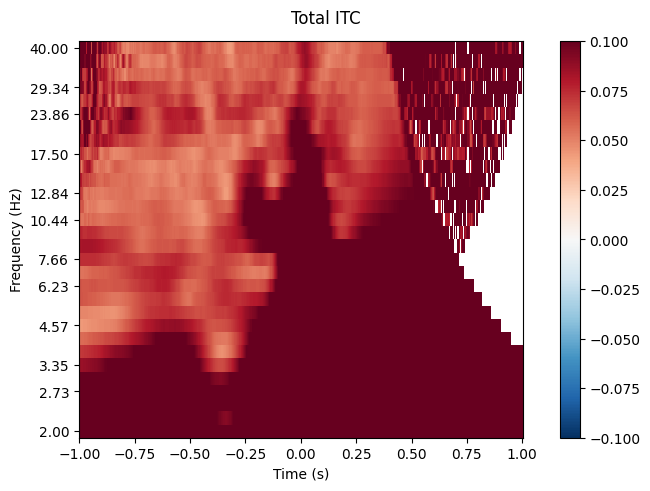

[<Figure size 640x480 with 2 Axes>]

In [168]:
itc.plot(picks=['all'], tmin=-1, tmax=1, title="Total ITC", combine='mean')

4. Plot TFR events

No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied


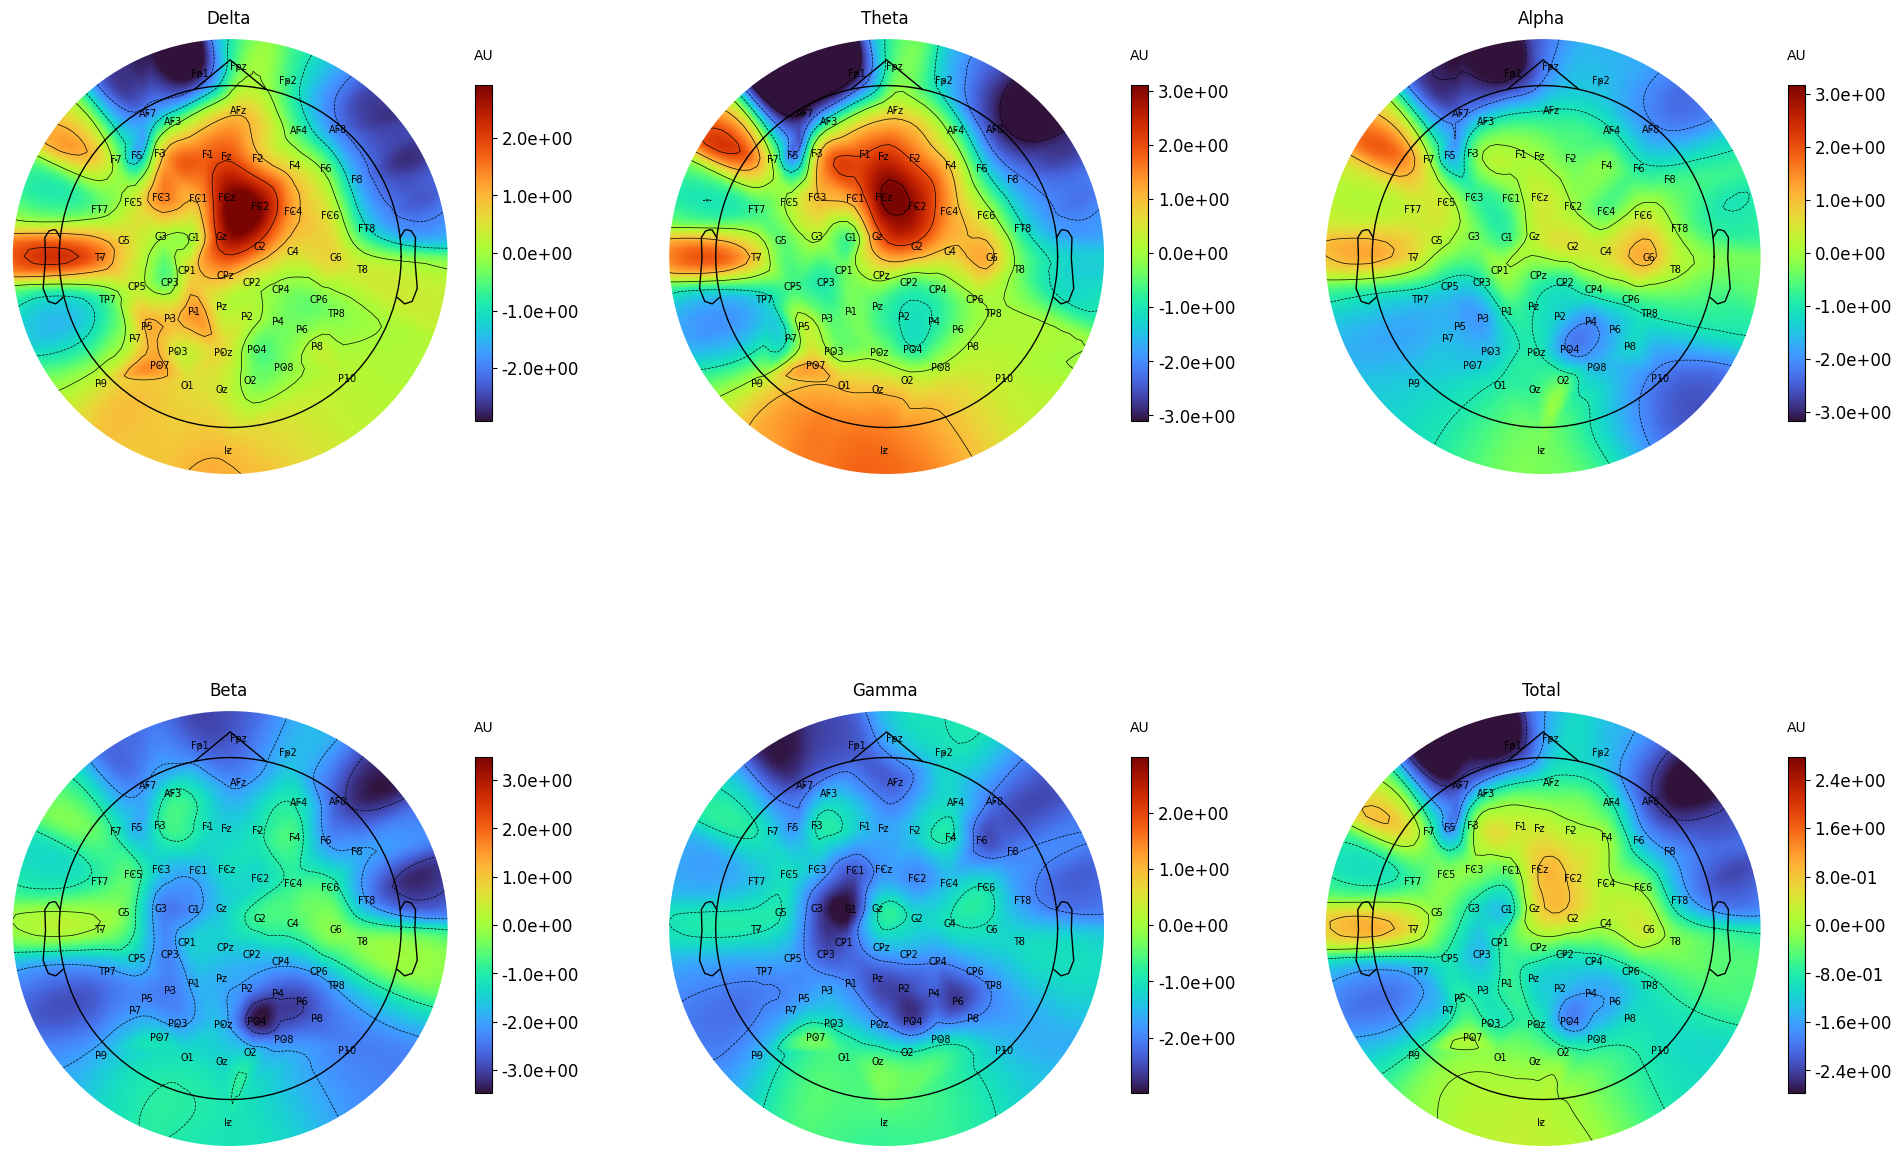

In [ ]:
AvT.plot_topomaps(tfr)

No baseline correction applied


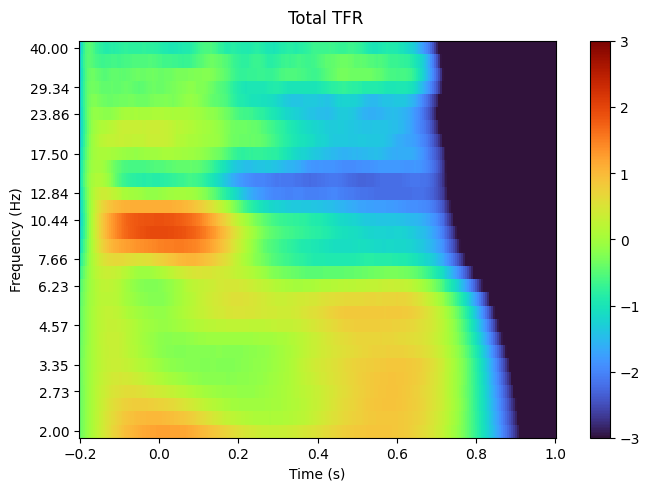

No baseline correction applied


c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\functions.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([round(x - t_event, 2) for x in ax.get_xticks()])


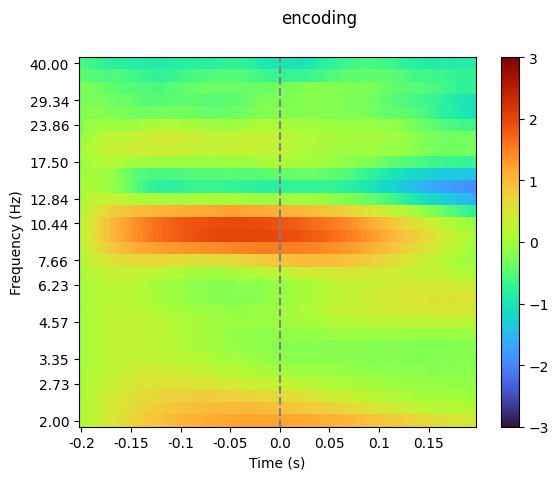

No baseline correction applied


c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\functions.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([round(x - t_event, 2) for x in ax.get_xticks()])


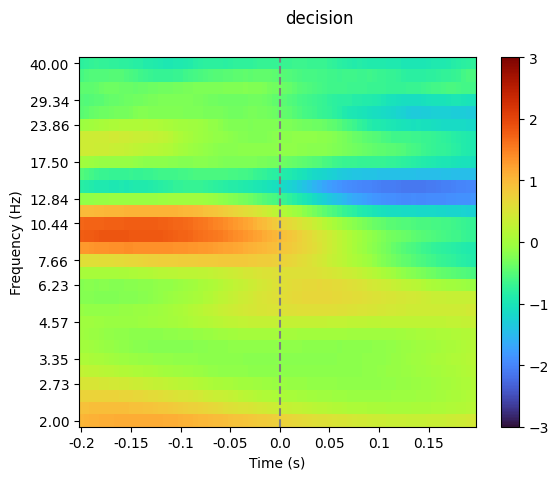

No baseline correction applied


c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\functions.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([round(x - t_event, 2) for x in ax.get_xticks()])


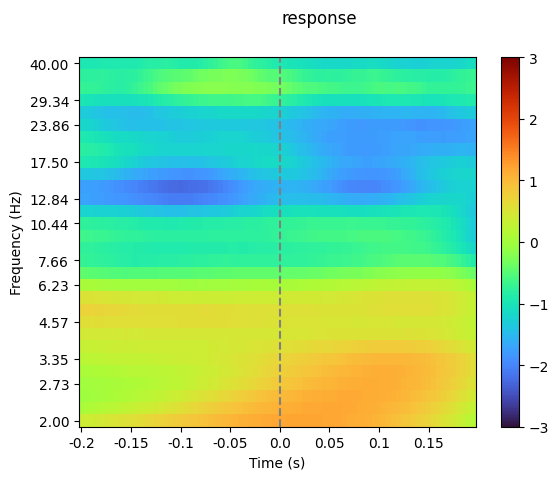

In [ ]:
#parameters
channels = ['all']                                                              #channels to be plotted
events = ['null', 'encoding', 'decision', 'confirmation', 'response']           #event labels
z_axis = (-3, 3)                                                                #power
x_axis = (-0.2, 1)                                                              #frequency (Hz)

#plot total TFR
tfr.plot(picks=channels, tmin=x_axis[0], tmax=x_axis[1], vlim=z_axis, title="Total TFR", cmap='turbo', combine='mean')


#plot single events
for n, event in enumerate(tfr_events):
    if np.any(~np.isnan(event._data)):
        AvT.plot_tfr_event(event, channels, events[n], z_axis)